# Homework 1: Social Network Analysis

In [1]:
import numpy as np
import scipy.sparse as ssp
from graphLib import Graph
from itertools import combinations
import matplotlib.pyplot as plt

## Example

In [2]:
#--- read the graph file and construct a graph
graph = Graph(ssp.load_npz('../data/example_graph.npz'))

In [3]:
# number of nodes in graph:
n = graph.n
print(n)

10


In [4]:
# get the adjacency matrix of graph

A = graph.get_adj_matrix()
print(A)

[[0 0 0 0 1 0 1 1 0 0]
 [0 0 1 0 0 0 0 0 1 0]
 [0 1 0 0 0 1 1 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [1 0 0 1 0 1 1 0 0 1]
 [0 0 1 0 1 0 0 0 0 0]
 [1 0 1 0 1 0 0 1 0 1]
 [1 0 0 0 0 0 1 0 0 1]
 [0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 1 1 0 0]]


In [5]:
# get adjacency list

adj_list = graph.get_adj_list()
for i in range(n):
	print(i, adj_list[i])

0 [np.int64(4), np.int64(6), np.int64(7)]
1 [np.int64(2), np.int64(8)]
2 [np.int64(1), np.int64(5), np.int64(6)]
3 [np.int64(4)]
4 [np.int64(0), np.int64(3), np.int64(5), np.int64(6), np.int64(9)]
5 [np.int64(2), np.int64(4)]
6 [np.int64(0), np.int64(2), np.int64(4), np.int64(7), np.int64(9)]
7 [np.int64(0), np.int64(6), np.int64(9)]
8 [np.int64(1)]
9 [np.int64(4), np.int64(6), np.int64(7)]


In [6]:
# get degree sequence

deg_seq = graph.get_deg_seq()
print(deg_seq)

[3 2 3 1 5 2 5 3 1 3]


## Task 1: Compute Graph Properties [45 points]

In [7]:
from task_1 import compute_deg_distr, get_cc_local, get_cc_global, get_diameter

### Task 1.1: Degree Distribution

In [8]:
#--- read the graph file and construct a graph
G1 = Graph(ssp.load_npz('../data/graph_ER.npz'))   # Erdos-Renyi graph, p = 0.3
G2 = Graph(ssp.load_npz('../data/graph_BA.npz'))   # Barabasi-Albert graph

In [9]:
#--- obtain degree sequence and associated counts
degs1,counts1=compute_deg_distr(G1)
degs2,counts2=compute_deg_distr(G2)

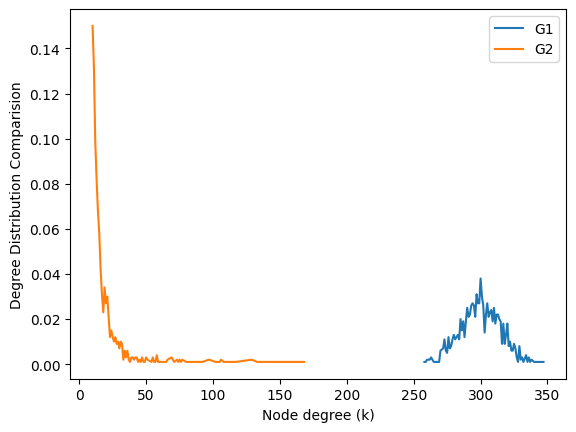

In [10]:
#--- plot the degree distribution
Pk1=counts1/G1.n
Pk2=counts2/G2.n
plt.plot(degs1, Pk1, label='G1')
plt.plot(degs2, Pk2, label='G2')
plt.xlabel('Node degree (k)')
plt.ylabel('P(k)')
plt.ylabel('Degree Distribution Comparision')
plt.legend()
plt.show()

### Task 1.2: Clustering Coefficients

In [11]:
for i in [0,5]:
    print(get_cc_local(graph,i))

TypeError: get_adj_matrix() takes 1 positional argument but 2 were given

In [ ]:
cc_global = get_cc_global(graph)

In [ ]:
print(cc_global)

### Task 1.3: Graph Diameter

In [ ]:
diameter = get_diameter(graph)

In [ ]:
print(diameter)

## Task 2: Compute Node Centralities [35 points]

In [ ]:
from task_2 import get_eigen_centrality, build_matrix, get_btw_c

### Task 2.1: Eigenvector Centrality

In [ ]:
# TODO: find the top-10 nodes and their eigenvector centralities

In [ ]:
eigenvector = get_eigen_centrality(graph)

### Task 2.2: Betweenness Centrality

In [ ]:
# build 2 global matrices: a distance matrix, and a matrix storing the number of shortest pathes
n = graph.n
distance_mat = np.zeros((n,n), dtype = int)
num_shortest_path_mat = np.zeros((n,n), dtype = int)

In [ ]:
# construct the two matrices - it is recommended you save the two matrices into files since they 
# take a lot of time to compute 
build_matrix(graph,distance_mat,num_shortest_path_mat)

In [ ]:
# TODO: compute the betweenness centrality for each node

In [ ]:
# compute centrality for node 0 (this is just an example)
centrality = get_btw_c(graph,5,distance_mat,num_shortest_path_mat)

## Task 3: Link Prediction [20 points]

In [ ]:
from task_3 import gen_net_obs, compute_Jaccard, compute_Katz, link_pred

graph = Graph(ssp.load_npz('../data/ws_graph.npz'))

# load the test edges and non_edges
test_edges = np.loadtxt('../data/target.edges',dtype = int)
test_non_edges = np.loadtxt('../data/target.nonedges', dtype = int)
pos_num = len(test_edges)
neg_num = len(test_non_edges)

# 1 denotes an edge; 0 denotes a non-edge
ground_truth = np.concatenate((np.ones(pos_num,dtype = int),np.zeros(neg_num,dtype = int)), axis = 0)

In [ ]:
# TODO: generate observed network

In [ ]:
adj_obs, test_set = gen_net_obs(graph, test_edges,test_non_edges)

In [ ]:
# TODO: Get similarity based on metric (Katz or Jaccard)

In [ ]:
jaccardsim = compute_Jaccard(adj_obs,test_set)
np.savetxt('../result/Jac_sim.txt', jaccardsim, fmt = '%f')

In [ ]:
katzsim = compute_Katz(adj_obs,test_set)
np.savetxt('../result/Katz_sim.txt', katzsim, fmt = '%f')

In [ ]:
# TODO: make prediction

In [ ]:
pred_jac=link_pred(adj_obs, test_set, 'Jaccard',0.1)
pred_katz=link_pred(adj_obs, test_set, 'Katz',0.02)

In [ ]:
# TODO: compute accuracy based on pred and groundtruth
# accuracy  =  correctly predicted node pairs/total number of pairs
acc_jac = 0

In [ ]:
acc_katz = 0

## Task 4: Generate Random Graphs [20 points]

### Task 4.1: Erdos-Renyi Graph [10 points]

In [ ]:
from task_4 import gen_ER, gen_BA

In [ ]:
# parameters - DO NOT CHANGE the seed
seed = 14
n = 200
p = 0.2
m = 5

# TODO: get the adj matrix A for erdos-renyi graphs
A_ER = gen_ER(n,p,seed)

# save the matrix A into file
ssp.save_npz('../result/task_4_graph_ER.npz', ssp.csr_matrix(A))

In [ ]:
degs_sorted = np.sort(sum(A_ER))

plt.plot(range(len(degs_sorted)),degs_sorted,'bo')
plt.ylabel('Degrees')
plt.show()

### Task 4.1: Erdos-Renyi Graph [10 points]

In [ ]:
# TODO: get the adj matrix A for BA graphs
A_BA = gen_BA(n,m,seed)

# save the matrix A into file
ssp.save_npz('../result/task_4_graph_BA.npz', ssp.csr_matrix(A))

### Task 4.2: Erdos-Renyi Graph [10 points]

In [ ]:
degs_sorted = np.sort(sum(A_BA))

plt.plot(range(len(degs_sorted)),degs_sorted,'bo')
plt.ylabel('Degrees')
plt.show()

## Task 5: Influence Maximization and Blocking [30 points]

In [ ]:
# parameters: DO NOT CHANGE
p = 0.05
mc = 5000
#k=10
k = 1

In [ ]:
from task_5 import greedySearch, modify_graph

In [ ]:
graph = Graph(ssp.load_npz('../data/example_graph.npz'))
#graph = Graph(ssp.load_npz('../data/BA_graph_100.npz'))

In [ ]:
seeds, influence = greedySearch(graph,k,p,mc)

In [ ]:
# we recommend saving the results into files
#np.savetxt('../result/IM_seeds.txt', seeds, fmt = '%s')
#np.savetxt('../result/IM_influence.txt', influence, fmt = '%f')

# uncomment these lines if you want to read the values instead of recalculating them 
# seeds = np.loadtxt('../result/IM_seeds.txt', dtype = int)
# influence = np.loadtxt('../result/IM_influence.txt', dtype = float)

In [ ]:
# randomly select nn nodes; DO NOT CHANGE nn=50 BELOW
#nn=50
nn=10
np.random.seed(15)
target_nodes = np.random.choice(range(graph.n), nn, replace = False)

# each node in seed_set will randomly block a neighbor 
# equivalently, delete the edge between that node and the neighbor

# create a modified graph
graph_new = Graph(modify_graph(graph,target_nodes))

# TODO: compute the seeds and influences over the new graph using the same parameters
seeds_new, influence_new = greedySearch(graph_new,k,p,mc)

#np.savetxt('../result/IM_seeds_new.txt', seeds_new, fmt = '%s')
#np.savetxt('../result/IM_influence_new.txt', influence_new, fmt = '%f')

# uncomment these lines if you want to read the values instead of recalculating them 
# seeds_new = np.loadtxt('../result/IM_seeds_new.txt', dtype = int)
# influence_new = np.loadtxt('../result/IM_influence_new.txt', dtype = float)

# plot in the same figure
plt.plot(range(k+1), influence,'-bo',range(k+1), influence_new,'-rs')
plt.show()